# 04 — Decide on a retention pilot

**Recommendation:** prepare a controlled pilot after validating business definitions and data chronology. The score concentrates departure labels in this dataset; it is insufficient to justify a full rollout or choose the most effective offer.

**Inputs:** training aggregates from 02, frozen test results and assumptions from 03, and the independent review of earlier steps in `reports/review.md`. **Transformations:** presentation and scenario calculations only. **Outputs:** decision tables and figures, plus `data/results/business_scenarios.csv`. No individual records are accessed, no model is trained and no strategy is selected after reading the test results.

The educational definition of `Exited` is documented in 01 through its match with the [Microsoft Learn example](https://learn.microsoft.com/en-us/fabric/data-science/customer-churn). Exact provenance, licensing and chronology are not certified. The study covers only the 10,000 supplied customers; representativeness is unknown.

In [1]:
from pathlib import Path
import json, hashlib, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown
ROOT = Path.cwd() if (Path.cwd() / 'brief.md').exists() else Path.cwd().parent
assert (ROOT / 'brief.md').exists(), 'Run from the project root or notebooks/'
sys.path.insert(0, str(ROOT / 'src'))
from presentation import display, en
SEED = 42
OUT = ROOT / 'data/results'
OUT.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({'figure.figsize': (9, 5), 'font.size': 11, 'axes.spines.top': False, 'axes.spines.right': False, 'text.parse_math': False})
def sha(path): return hashlib.sha256(Path(path).read_bytes()).hexdigest()

In [2]:
assert (ROOT/'reports/review.md').exists()
freeze=json.loads((OUT/'frozen_protocol.json').read_text())
result=json.loads((OUT/'test_evaluation.json').read_text())
assert result['freeze_sha256']==sha(OUT/'frozen_protocol.json')
segments=pd.read_csv(OUT/'segments_train.csv')
eda=json.loads((OUT/'eda_summary.json').read_text())
assert eda['source_split_sha256']==freeze['split_sha256']
assert result['selected_model']==freeze['selected_model']
strategy=pd.DataFrame(result['strategies'])
eco=freeze['economics']
chosen=result['metrics'][result['selected_model']]
ci=result['selected_bootstrap_ic95']
display(Markdown(f"""## What the study establishes

Among **{result['n_test']:,} test customers**, with **{result['positifs_test']} departure labels**, the model selected on validation is **{en(result['selected_model'])}**. Its ROC-AUC is **{chosen['roc_auc']:.3f}** (95% bootstrap CI {ci['roc_auc']['bas']:.3f}–{ci['roc_auc']['haut']:.3f}), and AP is **{chosen['average_precision']:.3f}**, compared with test prevalence of **{chosen['prevalence']:.1%}**. Brier is **{chosen['brier']:.3f}**.

At an illustrative capacity of **20%**, or **{chosen['contacts']} contacts**, predictive targeting concentrates **{chosen['departs_contactes']} departure labels**: precision **{chosen['precision_budget']:.1%}**, recall **{chosen['rappel_budget']:.1%}**, lift **{chosen['lift_budget']:.2f}**. The bootstrap interval for precision is {ci['precision_budget']['bas']:.1%}–{ci['precision_budget']['haut']:.1%} (1,000 resamples; fixed model).

These figures come from notebook 03. They assess retrospective ranking without evidence that features precede departure. Sigmoid calibration was selected for its better **validation** Brier score; its benefit is not guaranteed on the test set. The 20% quota is a capacity scenario, not a demonstrated optimal budget.
"""))

## What the study establishes

Among **2,000 test customers**, with **407 departure labels**, the model selected on validation is **Random forest (sigmoid)**. Its ROC-AUC is **0.857** (95% bootstrap CI 0.835–0.877), and AP is **0.685**, compared with test prevalence of **20.3%**. Brier is **0.105**.

At an illustrative capacity of **20%**, or **400 contacts**, predictive targeting concentrates **248 departure labels**: precision **62.0%**, recall **60.9%**, lift **3.05**. The bootstrap interval for precision is 56.0%–67.2% (1,000 resamples; fixed model).

These figures come from notebook 03. They assess retrospective ranking without evidence that features precede departure. Sigmoid calibration was selected for its better **validation** Brier score; its benefit is not guaranteed on the test set. The 20% quota is a capacity scenario, not a demonstrated optimal budget.


## Segments to investigate, without attributing causality

The diagnostic below reuses **training** aggregates, rather than searching for new segments on the test set. Intervals are exploratory 95% binomial Wilson intervals, without adjustment for multiple comparisons. Proportions are not annual: the label horizon is unknown. Age, country and activity describe associations that may reflect composition, selection or measurement after departure.

Bar labels give the observed proportion, and category labels give training counts.
Activity categories are compared horizontally; age bands follow their natural
order from left to right. Both axes start at zero. The percentage scales are
explicit and differ between these two panels. Whiskers retain the exploratory
95% intervals; the dashed line marks the overall training proportion.

,Dimension,Group,Training customers,Churn labels,Churn proportion,95% CI lower,95% CI upper
5,Activity,Inactive,2901,765,26.4%,24.8%,28.0%
6,Activity,Active,3099,457,14.7%,13.5%,16.0%
7,Products,1 product(s),3012,822,27.3%,25.7%,28.9%
8,Products,2 product(s),2777,220,7.9%,7.0%,9.0%
9,Products,3 product(s),172,141,82.0%,75.6%,87.0%
10,Products,4 product(s),39,39,100.0%,91.0%,100.0%
11,Age,18–34 years,2209,178,8.1%,7.0%,9.3%
12,Age,35–44 years,2420,436,18.0%,16.5%,19.6%
13,Age,45–54 years,853,414,48.5%,45.2%,51.9%
14,Age,55+ years,518,194,37.5%,33.4%,41.7%


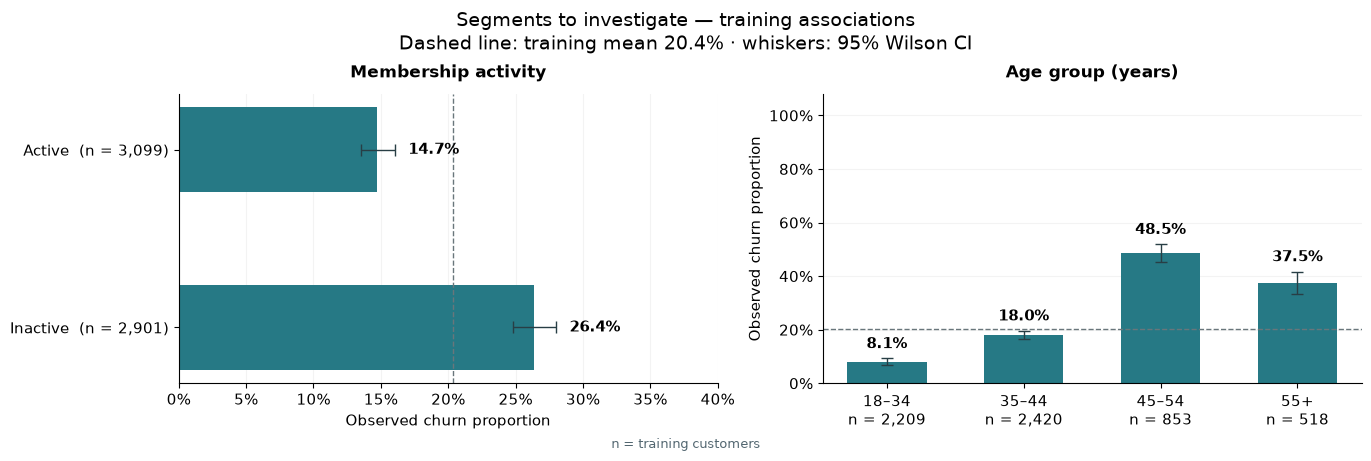

In [3]:
take=segments[segments.variable.isin(['IsActiveMember','AgeBand','NumOfProducts'])].copy()
var_names={'IsActiveMember':'Activity','AgeBand':'Age','NumOfProducts':'Products'}
def segment_name(r):
 if r.variable=='IsActiveMember': return 'Inactive' if r.segment=='0' else 'Active'
 if r.variable=='AgeBand': return r.segment+' years'
 return r.segment+' product(s)'
take['Groupe']=take.apply(segment_name,axis=1)
take['Dimension']=take.variable.map(var_names)
show=take[['Dimension','Groupe','n','departs','proportion','ic95_bas','ic95_haut']].rename(columns={'n':'Clients train','departs':'Labels départ','proportion':'Part départ','ic95_bas':'IC 95 % bas','ic95_haut':'IC 95 % haut'})
display(show.style.format({'Part départ':'{:.1%}','IC 95 % bas':'{:.1%}','IC 95 % haut':'{:.1%}'}))
from presentation import segment_rate_figure
segment_rate_figure(
    segments, ['IsActiveMember', 'AgeBand'], eda['prevalence_train'],
    title='Segments to investigate — training associations',
)
plt.show()

**Implications:** investigate inactivity journeys and the needs of customers holding several products with business owners, without assuming that a reminder or another product will prevent departure. The four-product group contains only 39 training customers: 39 observed departure labels do not imply future certainty. Country is also associated with the label (02); check differences in commercial scope before acting. Gender, described in 02, is excluded from the model, which does not guarantee the absence of indirect bias.

## Compare strategies at the same cost

All four rules were fixed in 03. The business rule ranks customers by `2 × inactive + 1 × age ≥45 years`, breaking ties with seed 42. Predictive targeting uses the sigmoid-calibrated forest selected on validation. Random targeting is a single fixed draw, not the best of multiple draws. Each campaign makes 400 contacts. No campaign is the incremental reference, with zero cost and zero gain.

Churn risk does not measure response to an offer. “Targeted departures” are labels that the policy would have targeted in this holdout, not departures prevented.

Repeated random targeting would target an expected 81.4 departure labels; the fixed draw targets 85.


,Strategy,Contacts,Churn labels targeted,Precision,Recall,Lift,Hypothetical cost (USD)
0,No contact,0,0,—,0.0%,—,0
1,Random,400,85,21.2%,20.9%,1.04,"4,000"
2,Business rule,400,169,42.2%,41.5%,2.08,"4,000"
3,Predictive,400,248,62.0%,60.9%,3.05,"4,000"


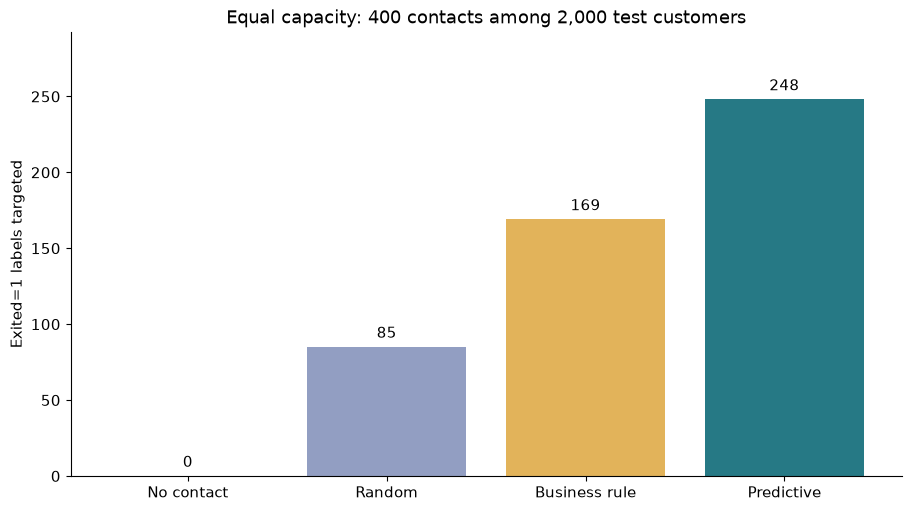

In [4]:
target_table=strategy[['strategie','contacts','departs_contactes','precision','rappel','lift','cout_scenario_eur']].rename(columns={'strategie':'Stratégie','contacts':'Contacts','departs_contactes':'Labels départ ciblés','precision':'Précision','rappel':'Rappel','lift':'Lift','cout_scenario_eur':'Coût hypothétique (USD)'})
display(target_table.style.format({'Précision':'{:.1%}','Rappel':'{:.1%}','Lift':'{:.2f}','Coût hypothétique (USD)':'{:,.0f}'},na_rep='—'))
fig,ax=plt.subplots(layout='constrained')
bars=ax.bar(strategy.strategie.map(en),strategy.departs_contactes,color=['#969696','#929ec2','#e2b35a','#267985'])
ax.bar_label(bars,padding=4)
ax.set(ylabel='Exited=1 labels targeted',title='Equal capacity: 400 contacts among 2,000 test customers',ylim=(0,strategy.departs_contactes.max()*1.18))
plt.show()
print(f"Repeated random targeting would target an expected {result['random_expected_departures']:.1f} departure labels; the fixed draw targets {int(strategy.loc[strategy.strategie.eq('Aléatoire'),'departs_contactes'].iloc[0])}.")

## Economic scenarios: quantify conditions, not measured ROI

All monetary values below are **illustrative US-dollar assumptions** using the numeric scenarios frozen in 03. None is supplied by campaign data. USD is the scenario's unit in this edition; file balances, whose currency is unknown, are not converted.

| Reference assumption | Value and convention |
|---|---|
| Economic horizon | H = 12 months, hypothetical; label horizon unknown |
| Contact | US\$2 per contacted customer |
| Offer | US\$8 paid to every contact, whether they stay or leave |
| Total cost | US\$10 per contact; US\$4,000 for 400 contacts |
| Net margin preserved | US\$500 per departure prevented over H, excluding campaign costs |
| Effect q | 20% of potential departures prevented among contacted customers |
| Eligibility and reachability | Assumed equal and complete |

For each policy: **simulated net gain = q × margin × targeted departure labels − cost × contacts**. Numbers of prevented departures are fractional expectations under assumptions, not observations. The supplied label is assumed to represent departure without a new campaign over H, with no effect on other customers and no interference. This transfer is unverified. No specific offer has been compared: an assumed uniform US\$8 offer does not establish its commercial relevance.

Fixed costs, implementation costs, long-term effects and opportunity costs are unspecified. This scenario is not a complete investment case. Margin must be measured as net contribution, never replaced by balance.

**Currency convention:** the US-dollar denomination was requested after the original evaluation. Numeric values are unchanged; this is a new stated currency for hypothetical assumptions, not a foreign-exchange conversion or a claim that the original protocol was denominated in USD. Historical `_eur` data fields stay unchanged to preserve the sealed numerical record.

In [5]:
scenarios=[]
for q in eco['effects']:
 for margin in eco['margins']:
  for cost in eco['costs']:
   for r in strategy.itertuples():
    scenarios.append({'strategie':r.strategie,'q':q,'marge_eur':margin,'cout_par_contact_eur':cost,'contacts':r.contacts,'labels_depart_cibles':r.departs_contactes,'departs_evites_attendus_scenario':q*r.departs_contactes,'budget_scenario_eur':cost*r.contacts,'gain_net_scenario_eur':q*margin*r.departs_contactes-cost*r.contacts})
scenarios=pd.DataFrame(scenarios)
reference=scenarios[(scenarios.q==eco['q']) & (scenarios.marge_eur==eco['margin_eur']) & (scenarios.cout_par_contact_eur==eco['cost_eur'])].copy()
# Check against the frozen scenario without accessing customer records.
pd.testing.assert_series_equal(reference.set_index('strategie').gain_net_scenario_eur.sort_index(),strategy.set_index('strategie').gain_net_scenario_eur.sort_index(),check_names=False,check_dtype=False)
reference['q_point_mort']=np.where(reference.labels_depart_cibles>0,reference.budget_scenario_eur/(reference.marge_eur*reference.labels_depart_cibles),np.nan)
display(reference[['strategie','contacts','labels_depart_cibles','departs_evites_attendus_scenario','budget_scenario_eur','gain_net_scenario_eur','q_point_mort']].rename(columns={'strategie':'Stratégie','contacts':'Contacts','labels_depart_cibles':'Labels ciblés','departs_evites_attendus_scenario':'Départs évités supposés','budget_scenario_eur':'Coût scénario (USD)','gain_net_scenario_eur':'Gain net scénario (USD)','q_point_mort':'q au point mort'}).style.format({'Départs évités supposés':'{:.1f}','Coût scénario (USD)':'{:,.0f}','Gain net scénario (USD)':'{:,.0f}','q au point mort':'{:.1%}'},na_rep='—'))
scenarios.to_csv(OUT/'business_scenarios.csv',index=False)

,Strategy,Contacts,Labels targeted,Assumed departures prevented,Scenario cost (USD),Scenario net gain (USD),Break-even q
88,No contact,0,0,0.0,0,0,—
89,Random,400,85,17.0,"4,000","4,500",9.4%
90,Business rule,400,169,33.8,"4,000","12,900",4.7%
91,Predictive,400,248,49.6,"4,000","20,800",3.2%


### Why risk and gain can have the same ranking

For a customer with risk p, hypothetical expected incremental gain is **p × q × M − c**. If q and M are positive and identical across customers, cost c is identical, and the number of contacts is fixed, maximizing the sum of risks maximizes this expectation. Individual break-even would be p > c/(qM), or 10% under the reference scenario; this does not establish that a 20% quota is optimal. Well-calibrated risk estimates are needed to interpret this expectation in US dollars.

At q=0, every 400-contact campaign loses its cost, so no contact is preferable. If offer response, margin, reachability or cost varies across customers, risk ranking may stop maximizing gain. A high-risk customer may be impossible to retain. The pilot must measure incremental effects. Randomized data can later support response comparisons or uplift modeling.

### Frozen sensitivity analysis, without selecting a new strategy

The q, margin and cost grid is the one frozen in 03. Capacity remains 400 contacts, so the budget varies with cost (US\$2,000, US\$4,000 or US\$8,000). Within each scenario, campaigns have identical budgets. This sensitivity analysis does not reoptimize models, quotas or segments on the test set.

Strategy,No contact,Random,Business rule,Predictive
Assumed fraction of departures prevented q,,,,
0%,US$0,"US$-4,000","US$-4,000","US$-4,000"
10%,US$0,US$250,"US$4,450","US$8,400"
20%,US$0,"US$4,500","US$12,900","US$20,800"
40%,US$0,"US$13,000","US$29,800","US$45,600"


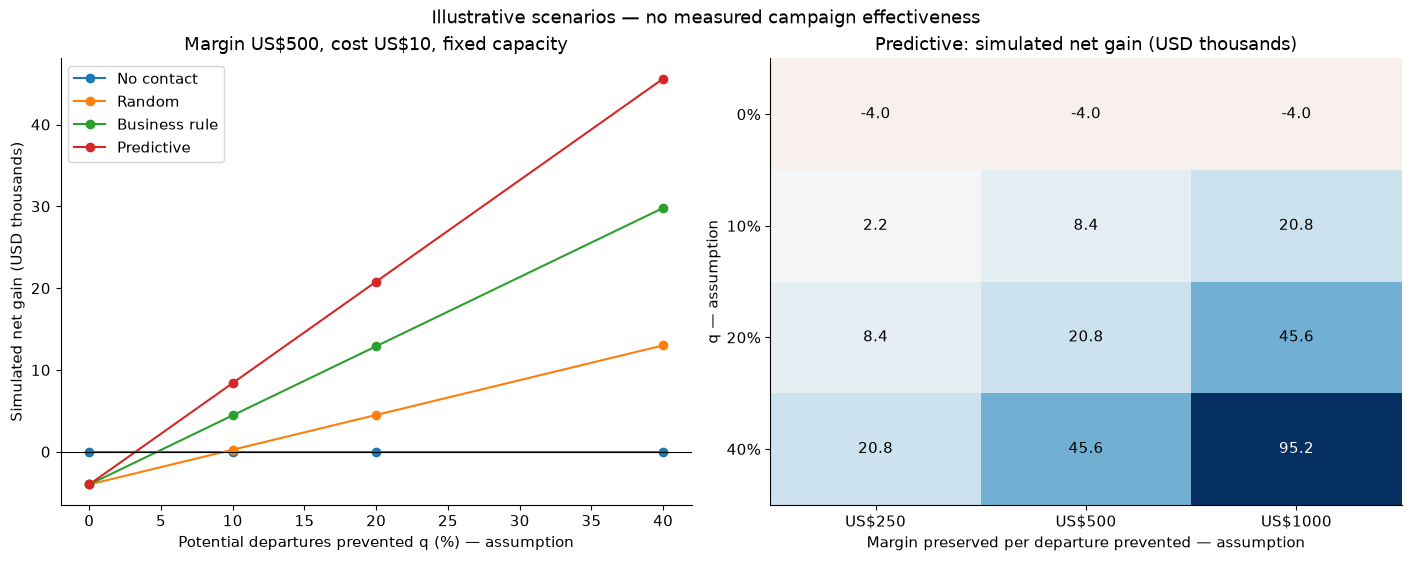

Under the reference scenario, predictive targeting yields **US\$20,800 in simulated net gain**, versus **US\$12,900** for the business rule, **US\$4,500** for random targeting and **US\$0** without a campaign. These are algebraic consequences of q=20%, M=US\$500, c=US\$10 and targeted labels, **not measured gains or a validated forecast**. If q=0, every campaign loses **US\$4,000**, and no campaign is preferable. Predictive targeting breaks even at approximately **3.2% of potential departures prevented** under these conventions; this is not an estimated effect.


In [6]:
base_sensitivity=scenarios[(scenarios.marge_eur==eco['margin_eur']) & (scenarios.cout_par_contact_eur==eco['cost_eur'])]
table=base_sensitivity.pivot(index='q',columns='strategie',values='gain_net_scenario_eur').reindex(columns=freeze['strategies'])
table.index=[f'{q:.0%}' for q in table.index]
table.index.name='Fraction supposée de départs évités q'
display(table.style.format('US${:,.0f}'))
fig,axes=plt.subplots(1,2,figsize=(14,5.5),layout='constrained')
for name,g in base_sensitivity.groupby('strategie',sort=False):
 axes[0].plot(g.q*100,g.gain_net_scenario_eur/1000,'o-',label=en(name))
axes[0].axhline(0,color='black',linewidth=.8)
axes[0].set(xlabel='Potential departures prevented q (%) — assumption',ylabel='Simulated net gain (USD thousands)',title='Margin US$500, cost US$10, fixed capacity')
axes[0].legend()
grid=scenarios[(scenarios.strategie=='Prédictif') & (scenarios.cout_par_contact_eur==eco['cost_eur'])].pivot(index='q',columns='marge_eur',values='gain_net_scenario_eur')
im=axes[1].imshow(grid/1000,cmap='RdBu',aspect='auto',vmin=-float(grid.to_numpy().max()/1000),vmax=float(grid.to_numpy().max()/1000))
axes[1].set_xticks(range(len(grid.columns)),[f'US${v}' for v in grid.columns])
axes[1].set_yticks(range(len(grid.index)),[f'{q:.0%}' for q in grid.index])
axes[1].set(xlabel='Margin preserved per departure prevented — assumption',ylabel='q — assumption',title='Predictive: simulated net gain (USD thousands)')
for i in range(len(grid)):
 for j in range(len(grid.columns)):
  value=grid.iloc[i,j]/1000
  axes[1].text(j,i,f'{value:.1f}',ha='center',va='center',color='white' if abs(value)>grid.to_numpy().max()/2000 else 'black')
fig.suptitle('Illustrative scenarios — no measured campaign effectiveness')
plt.show()
null=scenarios.query('q == 0')
assert (null.loc[null.contacts>0,'gain_net_scenario_eur']==-null.loc[null.contacts>0,'budget_scenario_eur']).all()
display(Markdown(f"""Under the reference scenario, predictive targeting yields **US\\$20,800 in simulated net gain**, versus **US\\$12,900** for the business rule, **US\\$4,500** for random targeting and **US\\$0** without a campaign. These are algebraic consequences of q=20%, M=US\\$500, c=US\\$10 and targeted labels, **not measured gains or a validated forecast**. If q=0, every campaign loses **US\\$4,000**, and no campaign is preferable. Predictive targeting breaks even at approximately **3.2% of potential departures prevented** under these conventions; this is not an estimated effect.
"""))

## Recommendations and remaining limitations

1. **Data and business owners:** confirm the churn convention, provenance and publication rights; define an eligible population, decision date t0 and horizon. Verify that every feature is available before t0 and every customer has complete follow-up. A future cohort and temporal test are required: the current random split does not demonstrate future performance.
2. **Retention and finance teams:** document real capacity, contact permissions, contact/offer costs, payment rules and net contribution over the horizon. Design an offer addressing customer needs and measure its effect. The US\$8 amount is a scenario, not an evidence-based offer recommendation.
3. **Data team:** retain the frozen policies as research references; check drift, calibration and errors by group on the new cohort. No score or metric here measures the effect of contact. Excluding gender does not guarantee fair treatment.
4. **Decision-maker:** fund a measurable pilot after these checks; do not extrapolate simulated gains to all 10,000 records or a real customer base. Without a temporal definition and campaign data, the optimal budget, best offer and actual ROI remain unidentified.

## Proposed randomized pilot with a control group

The following is a proposed protocol to register **before assignment and outcome observation**, on a new operational population. No pilot results exist.

| Item to prespecify | Concrete proposal |
|---|---|
| Population and score | Customers with an open account at t0 who are eligible and not in concurrent campaigns; features before t0, a dated cohort and a temporally validated score. Choose the final policy before recruitment. |
| Pilot scope | Top 20% of scores in the eligible batch; proposed quota to confirm against real capacity. Conclusions apply only to this targeted population. |
| Assignment | Customer-level 1:1 randomization to offer/contact versus no-new-campaign control; stratify by country and score band; persist assignments and prevent duplicate enrollment. |
| Intervention | One uniform offer and one channel defined before randomization; recorded payment rules; control receives usual service. Limit other contacts to reduce contamination and interference. |
| Horizon | Proposed H=12 months after t0, with precisely defined departure and complete follow-up in both arms; document censoring and missing data. |
| Primary outcome | Difference in mean net contribution per assigned customer over H, treatment minus control, **by intention to treat**. Include actual contact, offer and service costs, and realized margin. Do not substitute balance or gross revenue for contribution. |
| Hypothesis and success | Two-sided test at 5%. Proposed success: the lower bound of the 95% CI for net effect exceeds US\$0 per assigned customer. The US\$10 effect is for sample-size planning, not an expected gain or a second success condition; criteria must be ratified before randomization. Do not restrict conclusions to reachable customers or offer acceptors. |
| Secondary outcomes | Cumulative departure, offer uptake, reachability, complaints, opt-outs and costs; define incident stop thresholds with business owners before launch. Segment analyses remain exploratory unless multiple confirmatory tests are prespecified. |
| Sample size and power | 80% power, proposed minimum economically relevant effect US\$10. Under balanced allocation and a means approximation: n per arm ≈ 2 × (1.96+0.84)² × σ² / 10². Estimate contribution σ from comparable history or a blinded pilot phase, allow for expected loss to follow-up, then fix n. No reliable sample size is available without this variance; the 2,000 test customers are not a trial. |
| Analysis and stopping | Analyze after complete follow-up, with no opportunistic stopping at significance. Adjust estimates for randomization strata, use intervals robust to margin distributions, and specify missing-data treatment and sensitivity analysis before unblinding. |

This pilot will identify the intervention's effect **within the targeted population**. Alone, it cannot establish that the score is the best economic policy across the whole customer base. A later randomized comparison of policies, or randomized exploration outside the top-score group, is needed to generalize or learn heterogeneous responses.

**Traceability:** quality and protocol → 01; segments and intervals → 02; model selection, metrics, rules and frozen assumptions → 03; derived scenarios and proposed protocol → 04. Independent reviews remain in `reports/review.md`. Local HTML exports without code are prepared after priority findings are closed; nothing is deployed to the website.